# Inferences for Two Population Means Using Paired Samples
---

## Experiment: a paired t-test by hand and with SciPy.

In [1]:
import numpy as np
from scipy import stats

before = np.array([62, 71, 68, 74, 69, 77, 73, 66, 70, 75], dtype=float)
after = np.array([66, 73, 74, 75, 73, 79, 78, 68, 73, 80], dtype=float)

differences = after - before  # Positive means improvement.
n = len(differences)
mean_d = np.mean(differences)
sd_d = np.std(differences, ddof=1)
se_d = sd_d / np.sqrt(n)

t_manual = mean_d / se_d
p_manual = 2 * stats.t.sf(abs(t_manual), df=n - 1)
critical = stats.t.ppf(0.975, df=n - 1)
ci = (mean_d - critical * se_d, mean_d + critical * se_d)

paired_result = stats.ttest_rel(after, before)
one_sample_result = stats.ttest_1samp(differences, popmean=0)

print(f"Number of pairs: {n}")
print(f"Mean paired change: {mean_d:.3f}")
print(f"SD of changes: {sd_d:.3f}")
print(f"t statistic: {t_manual:.4f}")
print(f"Two-sided p-value: {p_manual:.6f}")
print(f"95% CI: ({ci[0]:.3f}, {ci[1]:.3f})")

# Experiment: reverse the subtraction order.
# Which results change sign, and which do not?

Number of pairs: 10
Mean paired change: 3.400
SD of changes: 1.647
t statistic: 6.5299
Two-sided p-value: 0.000108
95% CI: (2.222, 4.578)


## Experiment: the effect of within-pair correlation.

Within-pair correlation: 0.761
SE using paired differences: 0.788
SE ignoring pairing: 1.608


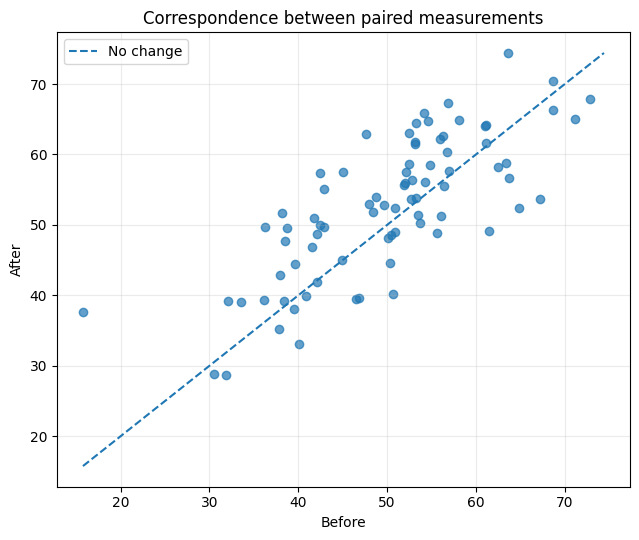

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)
n = 80

# The paired measurements have strong positive correlation.
pairs = rng.multivariate_normal(
    mean=[50, 52],
    cov=[[100, 80], [80, 100]],
    size=n
)

before, after = pairs[:, 0], pairs[:, 1]
d = after - before

paired_se = np.std(d, ddof=1) / np.sqrt(n)
wrong_unpaired_se = np.sqrt(
    np.var(before, ddof=1) / n + np.var(after, ddof=1) / n
)

print(f"Within-pair correlation: {np.corrcoef(before, after)[0, 1]:.3f}")
print(f"SE using paired differences: {paired_se:.3f}")
print(f"SE ignoring pairing: {wrong_unpaired_se:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(before, after, alpha=0.7)
limits = [min(before.min(), after.min()), max(before.max(), after.max())]
ax.plot(limits, limits, linestyle="--", label="No change")
ax.set_xlabel("Before")
ax.set_ylabel("After")
ax.set_title("Correspondence between paired measurements")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("../../images/paired_measurement_relationship.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: replace the off-diagonal covariance 80 with -80.
# How does the precision of the paired mean change?

## Experiment: diagnostic plots of paired differences.

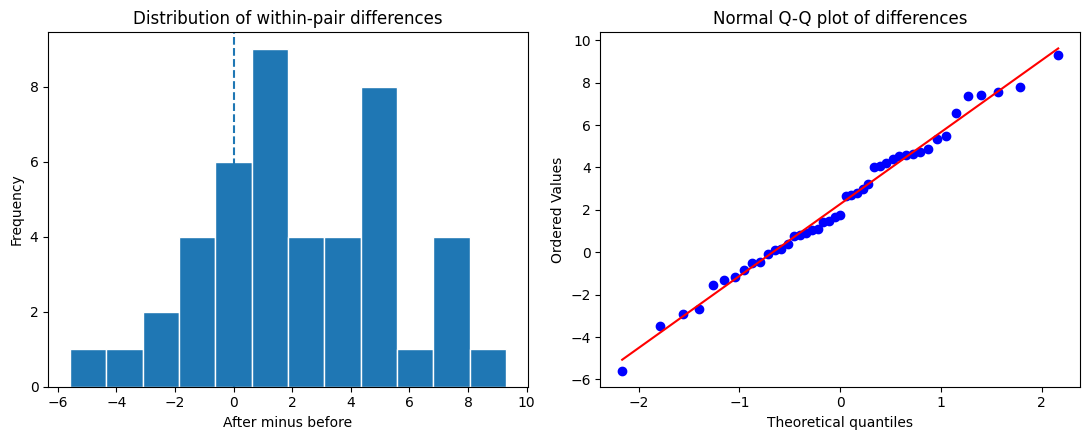

Paired t-test: TtestResult(statistic=4.595450922705204, pvalue=3.621478625103811e-05, df=44)


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
differences = rng.normal(loc=2.0, scale=4.0, size=45)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(differences, bins=12, edgecolor="white")
axes[0].axvline(0, linestyle="--")
axes[0].set_title("Distribution of within-pair differences")
axes[0].set_xlabel("After minus before")
axes[0].set_ylabel("Frequency")

stats.probplot(differences, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q plot of differences")
fig.tight_layout()
fig.savefig("../../images/paired_difference_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

print("Paired t-test:", stats.ttest_1samp(differences, popmean=0))

# Experiment: replace the last difference with 50.
# Examine the diagnostic plots and resulting test.

## Experiment: type I error with and without pairing.

Paired rejection rate under H0: 0.052
Ignoring pairs under H0:      0.000


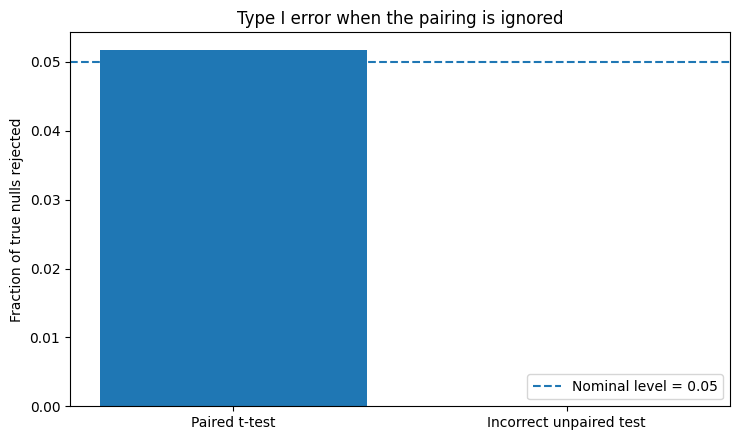

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
repetitions = 10_000
n = 24
alpha = 0.05

# Shared baselines yield positively correlated measurements.
baselines = rng.normal(100, 12, size=(repetitions, n))
before = baselines + rng.normal(0, 3, size=(repetitions, n))
after = baselines + rng.normal(0, 3, size=(repetitions, n))

d = after - before
se_paired = d.std(axis=1, ddof=1) / np.sqrt(n)
t_paired = d.mean(axis=1) / se_paired
p_paired = 2 * stats.t.sf(np.abs(t_paired), df=n - 1)

# Intentionally incorrect for these dependent samples:
wrong = stats.ttest_ind(after, before, axis=1, equal_var=False)
p_wrong = wrong.pvalue

rates = [np.mean(p_paired < alpha), np.mean(p_wrong < alpha)]
print(f"Paired rejection rate under H0: {rates[0]:.3f}")
print(f"Ignoring pairs under H0:      {rates[1]:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.bar(["Paired t-test", "Incorrect unpaired test"], rates)
ax.axhline(alpha, linestyle="--", label="Nominal level = 0.05")
ax.set_ylabel("Fraction of true nulls rejected")
ax.set_title("Type I error when the pairing is ignored")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/paired_vs_unpaired_type1.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: create negatively correlated pairs instead.
# Does ignoring the pairing remain conservative?

## Experiment: confidence-interval coverage and power.

n= 10: CI coverage=0.951, one-sided power=0.317
n= 20: CI coverage=0.949, one-sided power=0.532
n= 40: CI coverage=0.950, one-sided power=0.800
n= 80: CI coverage=0.949, one-sided power=0.971


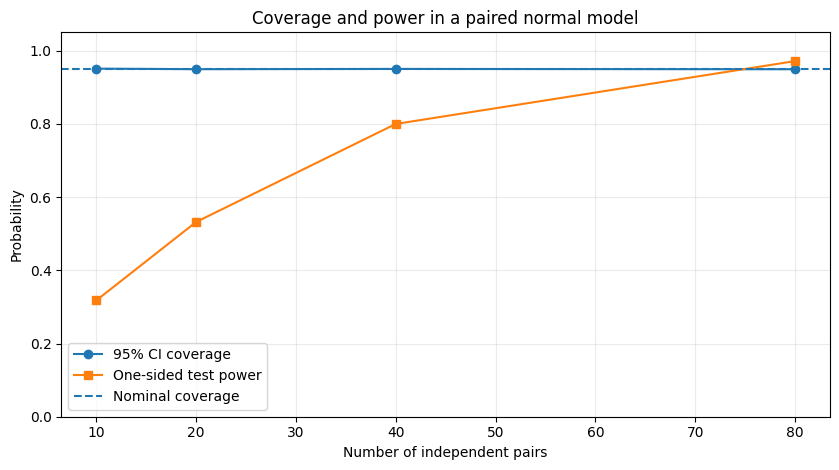

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
alpha = 0.05
mu_d = 2.0
sigma_d = 5.0
repetitions = 6_000
sample_sizes = [10, 20, 40, 80]

coverage = []
power = []

for n in sample_sizes:
    d = rng.normal(mu_d, sigma_d, size=(repetitions, n))
    means = d.mean(axis=1)
    se = d.std(axis=1, ddof=1) / np.sqrt(n)
    critical = stats.t.ppf(1 - alpha / 2, df=n - 1)

    lower = means - critical * se
    upper = means + critical * se
    coverage.append(np.mean((lower <= mu_d) & (mu_d <= upper)))

    # One-sided power for detecting a positive mean change.
    nc = np.sqrt(n) * mu_d / sigma_d
    cutoff = stats.t.ppf(1 - alpha, df=n - 1)
    power.append(stats.nct.sf(cutoff, df=n - 1, nc=nc))

for n, c, p in zip(sample_sizes, coverage, power):
    print(f"n={n:3d}: CI coverage={c:.3f}, one-sided power={p:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(sample_sizes, coverage, marker="o", label="95% CI coverage")
ax.plot(sample_sizes, power, marker="s", label="One-sided test power")
ax.axhline(0.95, linestyle="--", label="Nominal coverage")
ax.set_xlabel("Number of independent pairs")
ax.set_ylabel("Probability")
ax.set_ylim(0, 1.05)
ax.set_title("Coverage and power in a paired normal model")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/paired_ci_coverage_power.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: change the standard deviation of differences.
# How many pairs are needed for at least 80% power?

## Experiment: tutorial attendance and paired exam-score changes.

Tutorial attendance: 1
Pairs: 65; mean change: 1.415
One-sided paired t-test p-value: 0.03465
Tutorial attendance: 0
Pairs: 65; mean change: 0.431
One-sided paired t-test p-value: 0.25580
Difference in mean change: 0.985
Welch two-sided p-value for change difference: 0.32981


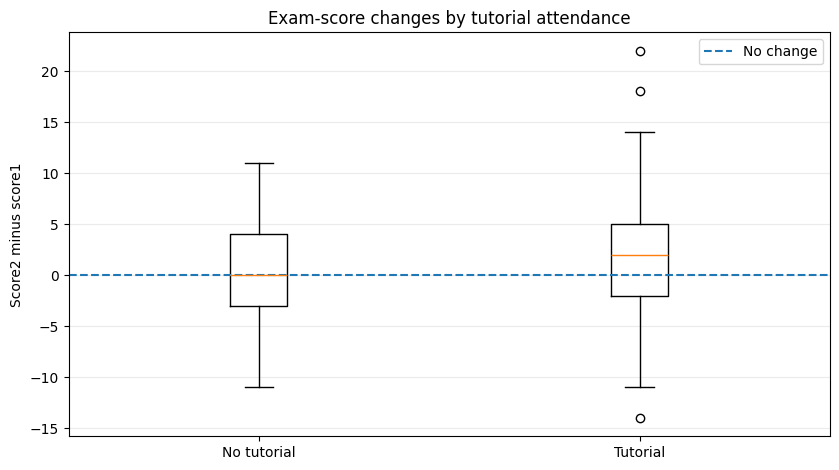

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
students = pd.read_csv(url)

columns = ["online.tutorial", "score1", "score2"]
complete = students[columns].copy()
for column in columns:
    complete[column] = pd.to_numeric(complete[column], errors="coerce")
complete = complete.dropna(subset=columns)

group_differences = {}
for tutorial, seed in [(1, 9), (0, 10)]:
    group = complete.loc[complete["online.tutorial"] == tutorial]
    if len(group) < 3:
        raise ValueError("At least three complete pairs are required per group")

    # Reproducible subsamples, as in the earlier SOGA-Py example.
    sample = group.sample(n=min(65, len(group)), random_state=seed)
    changes = sample["score2"].to_numpy() - sample["score1"].to_numpy()
    group_differences[tutorial] = changes

    test = stats.ttest_1samp(changes, popmean=0, alternative="greater")
    print(f"Tutorial attendance: {tutorial}")
    print(f"Pairs: {len(changes)}; mean change: {np.mean(changes):.3f}")
    print(f"One-sided paired t-test p-value: {test.pvalue:.5f}")

attended = group_differences[1]
not_attended = group_differences[0]

# Directly compare mean changes across the two independent groups.
comparison = stats.ttest_ind(attended, not_attended, equal_var=False)
print("Difference in mean change:", round(attended.mean() - not_attended.mean(), 3))
print("Welch two-sided p-value for change difference:", round(comparison.pvalue, 5))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.boxplot([not_attended, attended])
ax.set_xticks([1, 2], ["No tutorial", "Tutorial"])
ax.axhline(0, linestyle="--", label="No change")
ax.set_ylabel("Score2 minus score1")
ax.set_title("Exam-score changes by tutorial attendance")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig("../../images/paired_tutorial_score_changes.png", dpi=180, bbox_inches="tight")
plt.show()

## Experiment: sign and Wilcoxon signed-rank tests.

In [8]:
import numpy as np
from scipy import stats

# Most changes are positive, but one negative change is large.
d = np.array([1.2, 2.1, 0.8, 1.7, 1.5, 2.6,
              0.9, 1.8, 2.2, -25.0])

paired_t = stats.ttest_1samp(d, popmean=0)

# For the sign test, exclude exact zeros and count positive signs.
nonzero = d[d != 0]
positive = np.count_nonzero(nonzero > 0)
sign_test = stats.binomtest(
    positive, n=len(nonzero), p=0.5, alternative="two-sided"
)

# Supply the already calculated differences directly.
wilcoxon = stats.wilcoxon(d, alternative="two-sided")

print(f"Mean change: {np.mean(d):.3f}")
print(f"Median change: {np.median(d):.3f}")
print(f"Paired t-test p-value: {paired_t.pvalue:.5f}")
print(f"Sign-test p-value: {sign_test.pvalue:.5f}")
print(f"Wilcoxon signed-rank p-value: {wilcoxon.pvalue:.5f}")

# Experiment: replace -25 by -2.5.
# How do the three methods react to the changed magnitude?

Mean change: -1.020
Median change: 1.600
Paired t-test p-value: 0.71137
Sign-test p-value: 0.02148
Wilcoxon signed-rank p-value: 0.08398
